In [4]:
import torch
from torch.utils.data import DataLoader
import numpy as np
import os
import matplotlib.pyplot as plt
import glob
from matplotlib.colors import Normalize
MAIN_PATH = '/home/qiboxu/Database/U_NET/EMDB_PDB_for_U_Net/Filtered_Dateset/Training/TEST_with_blank'
idx = 2

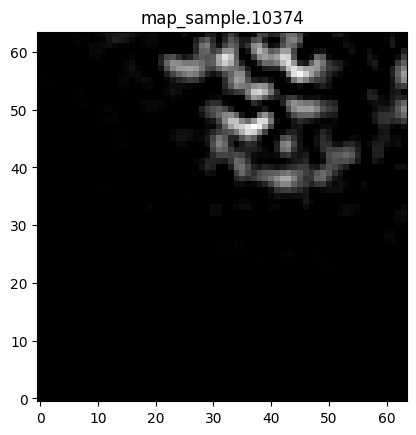

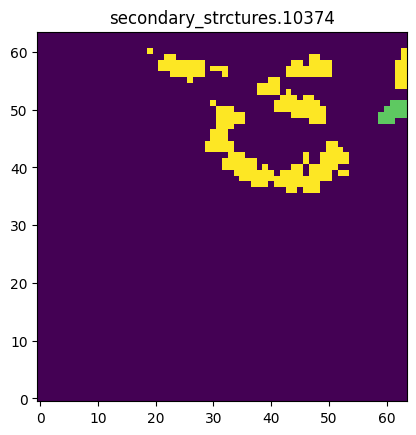

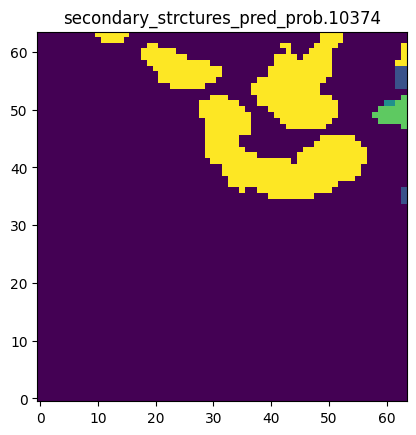

###


In [2]:
# test generatred data
import numpy as np
import matplotlib.pyplot as plt

for num in range(10374, 10375):
    model_type = 'map_sample'
    mapname = f'/home/qiboxu/Database/U_NET/EMDB_PDB_for_U_Net/Filtered_Dateset/Training/TEST_20240520/train_val_data/val/{model_type}/map.{num}.npy'
    aaa = np.load(mapname)
    # print(np.max(aaa))
    plt.imshow(aaa[:, :, 30], cmap='gray', origin='lower')
    plt.title(f'{model_type}.{num}')
    plt.show()

    model_type = 'secondary_strctures'
    filename = f'/home/qiboxu/Database/U_NET/EMDB_PDB_for_U_Net/Filtered_Dateset/Training/TEST_20240520/train_val_data/val/{model_type}/model_{model_type}.{num}.npy'
    aaa = np.load(filename)
    plt.imshow(aaa[:, :, 30], origin='lower')
    plt.title(f'{model_type}.{num}')
    plt.show()

    model_type = 'secondary_strctures_pred_prob'
    filename = f'/home/qiboxu/Database/U_NET/EMDB_PDB_for_U_Net/Filtered_Dateset/Training/TEST_20240520/train_val_data/val/{model_type}/{model_type}.{num}.npy'
    aaa = np.load(filename)
    # print(aaa.shape)
    plt.imshow(np.argmax(aaa, 0)[:, :, 30], origin='lower')
    plt.title(f'{model_type}.{num}')
    plt.show()
    print("###")

In [21]:
data_path = os.path.join(MAIN_PATH, 'train_val_data', 'train')

x0_name = 'map_sample'
x1_name = 'secondary_strctures'
x2_name = 'key_atoms'
x3_name = 'residue_types'
y1_name = f'{x1_name}_pred_prob'
y2_name = f'{x2_name}_pred_prob'
# y3_name = f'{x3_name}_pred_prob'

x0_list = sorted(glob.glob(os.path.join(data_path, x0_name, '*')))
x1_list = sorted(glob.glob(os.path.join(data_path, x1_name, '*')))
x2_list = sorted(glob.glob(os.path.join(data_path, x2_name, '*')))
x3_list = sorted(glob.glob(os.path.join(data_path, x3_name, '*')))
y1_list = sorted(glob.glob(os.path.join(data_path, y1_name, '*')))
y2_list = sorted(glob.glob(os.path.join(data_path, y2_name, '*')))
# y3_list = sorted(glob.glob(os.path.join(data_path, y3_name, '*')))

x0 = np.load(x0_list[idx])
x1 = np.load(x1_list[idx])
x2 = np.load(x2_list[idx])
x3 = np.load(x3_list[idx])
y1 = np.load(y1_list[idx])
y2 = np.load(y2_list[idx])
# y3 = np.load(y3_list[idx])

In [22]:
# ## for check map and model files - they are all good

# plt.figure(figsize=(12, 12))


# for ii in range(19, 58, 19):
#     pos = ii // 18


#     plt.subplot(3, 4, 4 * pos - 3, label=f'subplot{ii}')
#     plt.imshow(x0[ii, :, :], cmap='gray', origin="lower")
#     plt.title(f'model (z_slice={ii})')
#     # print(f'{x0_list[idx]}')

#     plt.subplot(3, 4, 4 * pos - 2, label=f'subplot{ii}')
#     plt.imshow(x1[ii, :, :], origin="lower")
#     plt.title(f'model (z_slice={ii})')
#     # print(f'{x1_list[idx]}')

#     plt.subplot(3, 4, 4 * pos - 1, label=f'subplot{ii}')
#     plt.imshow(x2[ii, :, :], origin="lower")
#     plt.title(f'model (z_slice={ii})')
#     # print(f'{x2_list[idx]}')

#     plt.subplot(3, 4, 4 * pos, label=f'subplot{ii}')
#     plt.imshow(x3[ii, :, :], origin="lower")
#     plt.title(f'model (z_slice={ii})')
#     # print(f'{x3_list[idx]}')

In [23]:
print(y1_list[idx])
y10 = np.max(y1[0]) #0.2
y11 = np.max(y1[1]) #0.21
y12 = np.max(y1[2]) #0.198
y13 = np.max(y1[3]) #0.20
y14 = np.max(y1[4]) #0.18
print(y10, y11, y12, y13, y14)

/home/qiboxu/Database/U_NET/EMDB_PDB_for_U_Net/Filtered_Dateset/Training/TEST_with_blank/train_val_data/train/secondary_strctures_pred_prob/secondary_strctures_pred_prob.10.npy
0.2020269 0.21705878 0.19914962 0.2056066 0.18947089


In [5]:
data_path = os.path.join(MAIN_PATH, 'ready_to_train_and_val')

x0_name = 'map_sample'
x1_name = 'secondary_strctures'
x2_name = 'key_atoms'
x3_name = 'residue_types'
y1_name = f'{x1_name}_pred_prob'
y2_name = f'{x2_name}_pred_prob'
y3_name = f'{x3_name}_pred_prob'
z1_name = f'{y1_name}-test'
z2_name = f'{y2_name}-test'
z3_name = f'{y3_name}-test'

# x0_list = sorted(glob.glob(os.path.join(data_path, x0_name, '*')))
# x1_list = sorted(glob.glob(os.path.join(data_path, x1_name, '*')))
# x2_list = sorted(glob.glob(os.path.join(data_path, x2_name, '*')))
# x3_list = sorted(glob.glob(os.path.join(data_path, x3_name, '*')))
# y1_list = sorted(glob.glob(os.path.join(data_path, y1_name, '*')))
# y2_list = sorted(glob.glob(os.path.join(data_path, y2_name, '*')))
# y3_list = sorted(glob.glob(os.path.join(data_path, y3_name, '*')))
# z1_list = sorted(glob.glob(os.path.join(data_path, z1_name, '*')))
z2_list = sorted(glob.glob(os.path.join(data_path, z2_name, '*')))
# z3_list = sorted(glob.glob(os.path.join(data_path, z3_name, '*')))


# x0 = np.load(x0_list[idx])
# x1 = np.load(x1_list[idx])
# x2 = np.load(x2_list[idx])
# x3 = np.load(x3_list[idx])
# y1 = np.load(y1_list[idx])
# y2 = np.load(y2_list[idx])
# y3 = np.load(y3_list[idx])
# z1 = np.load(z1_list[idx])
z2 = np.load(z2_list[idx])
# z3 = np.load(z3_list[idx])


In [ ]:
print(z1_list[idx])

z10 = np.max(z1[0]) #0.2
z11 = np.max(z1[1]) #0.21
z12 = np.max(z1[2]) #0.198
z13 = np.max(z1[3]) #0.20
z14 = np.max(z1[4]) #0.18
print(z10, z11, z12, z13, z14)

In [7]:
print(z2_list[idx])

z20 = np.max(z2[0]) #0.2
z21 = np.max(z2[1]) #0.21
z22 = np.max(z2[2]) #0.198
z23 = np.max(z2[3]) #0.20
print(z20, z21, z22, z23)

/home/qiboxu/Database/U_NET/EMDB_PDB_for_U_Net/Filtered_Dateset/Training/TEST_with_blank/ready_to_train_and_val/key_atoms_pred_prob-test/key_atoms_pred_prob.10001.npy
1.0 0.9999999 0.9999994 0.99999976


In [26]:
# torch.softmax(model(cube), 1)
# yyy = np.argmax(y1, axis=0)
# print(yyy[19])
# yyy = np.argmax(yy, axis=0)
# print(yyy.shape)
# np.max(yy)